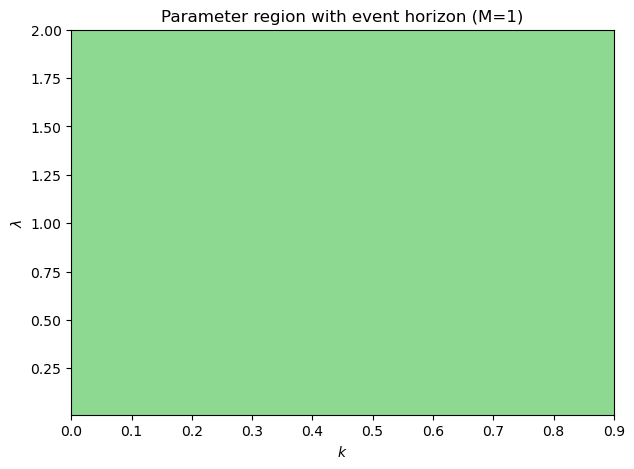

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

M = 1

def f(r, k, lam):
    return 1/(1-k) - 2*M/r + lam/r*np.log(r/lam)


# check if horizon exists
def horizon_exists(k, lam):
    r_values = np.logspace(-3, 3, 500)

    vals = [f(r, k, lam) for r in r_values]

    for i in range(len(r_values)-1):
        if vals[i]*vals[i+1] < 0:
            return True
    return False


# parameter ranges
k_values = np.linspace(0, 0.9, 150)
lam_values = np.linspace(0.01, 2, 150)

region = np.zeros((len(lam_values), len(k_values)))


for i, lam in enumerate(lam_values):
    for j, k in enumerate(k_values):
        if horizon_exists(k, lam):
            region[i,j] = 1


plt.figure(figsize=(7,5))

plt.contourf(
    k_values,
    lam_values,
    region,
    levels=[0,0.5,1],
    alpha=0.7
)

plt.xlabel(r"$k$")
plt.ylabel(r"$\lambda$")
plt.title("Parameter region with event horizon (M=1)")

plt.show()